# Dataset Class

In [2]:
import os
import cv2
import torch
from torch.utils.data import Dataset
import numpy as np

class LITSSliceDataset(Dataset):
    def __init__(self, image_dirs, mask_root, transform=None):
        self.image_paths = []
        self.mask_root = mask_root
        self.transform = transform

        for folder in image_dirs:
            self.image_paths.extend(sorted([
                os.path.join(folder, f)
                for f in os.listdir(folder)
                if f.endswith(".png")
            ]))

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        fname = os.path.basename(image_path)
    
        vol_id, slice_id = fname.replace(".png", "").split("_")[1], fname.replace(".png", "").split("_")[3]
        mask_path = os.path.join(self.mask_root, f"volume_{vol_id}", f"mask_{vol_id}_slice_{slice_id}.png")
    
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
    
        image = np.expand_dims(image, axis=-1)  # [H, W, 1]
        mask = np.expand_dims(mask, axis=-1)    # [H, W, 1]
    
        augmented = self.transform(image=image, mask=mask)
        image = augmented["image"]              # [1, H, W]
        mask = augmented["mask"]                # Should now also be [1, H, W]

        if mask.ndim == 4:
            mask = mask.permute(0, 3, 1, 2).squeeze(0)
        elif mask.ndim == 3 and mask.shape[0] != 1:
            mask = mask.permute(2, 0, 1)
        
        return image, mask

    def __len__(self):
        return len(self.image_paths)



In [4]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, p=0.5),
    A.Affine(scale=(0.95, 1.05), translate_percent=(0.05, 0.05), rotate=0, p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.GaussNoise(std_range=(0.01, 0.05), mean_range=(0.0, 0.0), p=0.3),
    A.ElasticTransform(alpha=1, sigma=50, p=0.2),
    A.GridDistortion(num_steps=5, distort_limit=0.03, p=0.2),
    A.CoarseDropout(num_holes_range=(1, 1), hole_height_range=(10, 20), hole_width_range=(10, 20), fill=0, fill_mask=0, p=0.3),
    A.CLAHE(clip_limit=2.0, p=0.3),
    A.Resize(256, 256),
    A.Normalize(mean=0.0, std=1.0, max_pixel_value=1.0),
    ToTensorV2()
], additional_targets={'mask': 'mask'})


C:\Users\Student\AppData\Roaming\Python\Python312\site-packages\albumentations\__init__.py:28: UserWarning: A new version of Albumentations is available: '2.0.8' (you have '2.0.7'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


In [6]:

full_dataset = LITSSliceDataset(
    image_dirs=["LITS/1_liver/"],
    mask_root="LITS_masks/",
    transform=train_transform  # Use augmentation for training
)


In [8]:
# from torch.utils.data import random_split

# train_size = int(0.8 * len(full_dataset))
# test_size = len(full_dataset) - train_size

# train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])


In [10]:
from torch.utils.data import random_split
import torch

# Define split sizes
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size

# Use a fixed seed for reproducibility
generator = torch.Generator().manual_seed(42)

# Split with seed
train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size], generator=generator)


In [12]:
from torch.utils.data import DataLoader


val_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=0.0, std=1.0, max_pixel_value=1.0),
    ToTensorV2()
])

# Apply val_transform manually to test set
test_dataset.dataset.transform = val_transform

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)


# UNET Model

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class UNetBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()
        # Encoder
        self.enc1 = UNetBlock(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = UNetBlock(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = UNetBlock(128, 256)
        self.pool3 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = UNetBlock(256, 512)

        # Decoder
        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = UNetBlock(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = UNetBlock(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = UNetBlock(128, 64)

        # Output
        self.out_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))

        # Bottleneck
        bn = self.bottleneck(self.pool3(e3))

        # Decoder
        d3 = self.dec3(torch.cat([self.up3(bn), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        out = torch.sigmoid(self.out_conv(d1))
        return out


In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet().to(device)


In [19]:
device

device(type='cuda')

# loss Function

In [22]:
def dice_loss(pred, target, smooth=1e-6):
    pred = pred.contiguous()
    target = target.contiguous()
    
    intersection = (pred * target).sum(dim=(2, 3))
    union = pred.sum(dim=(2, 3)) + target.sum(dim=(2, 3))
    
    dice = (2. * intersection + smooth) / (union + smooth)
    return 1 - dice.mean()


In [24]:
bce_loss = nn.BCELoss()

def combined_loss(pred, target):
    return 0.5 * bce_loss(pred, target) + 0.5 * dice_loss(pred, target)


In [26]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


# Training Loop

In [28]:
import time
import torch

def train(model, dataloader, optimizer, device, epochs=20):
    model.train()
    for epoch in range(epochs):
        start_time = time.time()  #  Start timing
        
        epoch_loss = 0.0
        print(f"\n🟢 Epoch {epoch+1}/{epochs}")


        for i, (img, mask) in enumerate(dataloader):

            img = img.to(device)
            mask = mask.to(device)


            optimizer.zero_grad()
            output = model(img)
            loss = combined_loss(output, mask)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        avg_loss = epoch_loss / len(dataloader)
        end_time = time.time()
        epoch_duration = end_time - start_time

        print(f" Epoch {epoch+1} Completed | Avg Loss: {avg_loss:.4f}")
        print(f" Time taken: {epoch_duration:.2f} seconds")

        #  Save model every 5 epochs
        if (epoch + 1) % 5 == 0:
            torch.save(model.state_dict(), f"unet_epoch_{epoch+1}_fulldataset_augmented_lits_chaos_seeded.pth")
            print(f" Model saved as 'unet_epoch_{epoch+1}.pth'")


In [83]:
train(model, train_loader, optimizer, device, epochs=20)


🟢 Epoch 1/20
 Epoch 1 Completed | Avg Loss: 0.3600
 Time taken: 369.22 seconds

🟢 Epoch 2/20
 Epoch 2 Completed | Avg Loss: 0.2348
 Time taken: 312.72 seconds

🟢 Epoch 3/20
 Epoch 3 Completed | Avg Loss: 0.1516
 Time taken: 313.06 seconds

🟢 Epoch 4/20
 Epoch 4 Completed | Avg Loss: 0.0990
 Time taken: 313.22 seconds

🟢 Epoch 5/20
 Epoch 5 Completed | Avg Loss: 0.0723
 Time taken: 312.88 seconds
 Model saved as 'unet_epoch_5.pth'

🟢 Epoch 6/20
 Epoch 6 Completed | Avg Loss: 0.0530
 Time taken: 312.84 seconds

🟢 Epoch 7/20
 Epoch 7 Completed | Avg Loss: 0.0443
 Time taken: 312.81 seconds

🟢 Epoch 8/20
 Epoch 8 Completed | Avg Loss: 0.0400
 Time taken: 313.17 seconds

🟢 Epoch 9/20
 Epoch 9 Completed | Avg Loss: 0.0364
 Time taken: 312.81 seconds

🟢 Epoch 10/20
 Epoch 10 Completed | Avg Loss: 0.0310
 Time taken: 312.92 seconds
 Model saved as 'unet_epoch_10.pth'

🟢 Epoch 11/20
 Epoch 11 Completed | Avg Loss: 0.0279
 Time taken: 312.61 seconds

🟢 Epoch 12/20
 Epoch 12 Completed | Avg Loss

In [388]:
torch.cuda.empty_cache()

In [25]:
torch.save(model.state_dict(), "unet_liver_final_fulldataset_augmented.pth")

# Test the model on randomly selected image from dataset

In [338]:
import random
import matplotlib.pyplot as plt

def visualize_random_prediction(model, dataset, device):
    model.eval()
    
    # Pick a random sample from test set
    idx = random.randint(0, len(dataset) - 1)
    img, gt_mask = dataset[idx]

    # Move to device and predict
    img_batch = img.unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(img_batch).squeeze().cpu().numpy()
    
    img_np = img.squeeze().cpu().numpy()
    gt_np = gt_mask.squeeze().cpu().numpy()
    pred_binary = (pred > 0.5).astype(np.uint8)

    # Plot the three visualizations
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))

    # 1. CT + Predicted Mask
    ax[0].imshow(img_np, cmap='gray')
    ax[0].imshow(pred_binary, cmap='Reds', alpha=0.4)
    ax[0].set_title("Predicted Mask Overlay")
    ax[0].axis('off')

    # 2. CT + Ground Truth Mask
    ax[1].imshow(img_np, cmap='gray')
    ax[1].imshow(gt_np, cmap='Blues', alpha=0.4)
    ax[1].set_title("Ground Truth Mask Overlay")
    ax[1].axis('off')

    # 3. Raw CT Image
    ax[2].imshow(img_np, cmap='gray')
    ax[2].set_title("Original Liver CT Slice")
    ax[2].axis('off')

    plt.tight_layout()
    plt.show()


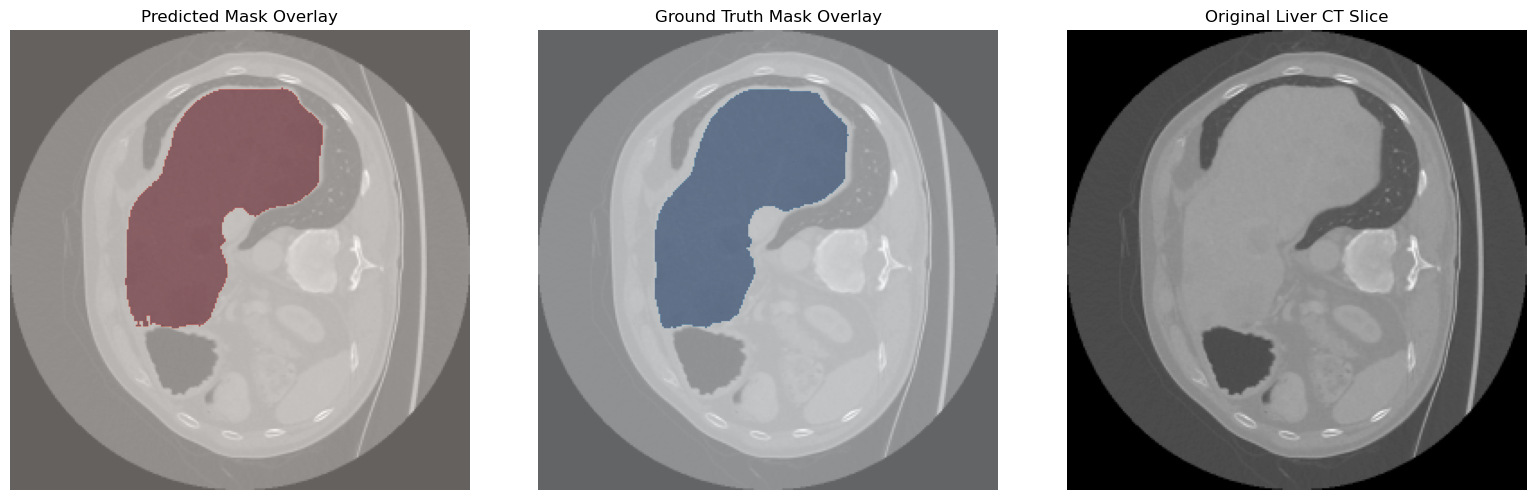

In [429]:
visualize_random_prediction(model, test_dataset, device)


In [342]:
import os
import random
import re
import cv2
import matplotlib.pyplot as plt
import torch
import numpy as np

def test_chaos_sample(model, device,
                      image_folder="../chaos_dataset/1_liver",
                      mask_root="../chaos/Train_Sets/CT",
                      use_clahe=True):
    # Pick a random CHAOS CT image
    filenames = [f for f in os.listdir(image_folder) if f.endswith(".png")]
    fname = random.choice(filenames)
    print(f"📂 Random CHAOS slice selected: {fname}")

    # Extract patient ID
    parts = fname.replace(".png", "").split("_")
    patient_id = parts[1]  # '1' or '30'

    # Extract slice number using regex (prefer 'i' or 'IMG' pattern)
    img_match = re.search(r'i(\d{3,})', fname) or re.search(r'IMG-\d{4}-(\d{3,})', fname)
    if img_match:
        slice_num = int(img_match.group(1))
    else:
        all_numbers = re.findall(r'\d+', fname)
        slice_num = int(all_numbers[-1])

    slice_str = f"{slice_num:03d}"

    # Build full paths
    image_path = os.path.join(image_folder, fname)
    mask_path = os.path.join(mask_root, patient_id, "Ground", f"liver_GT_{slice_str}.png")

    print(f"Using mask path: {mask_path}")
    if not os.path.exists(mask_path):
        print("❌ Mask file does NOT exist!")
        return
    else:
        print("✅ Mask file found.")

    # Load image
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    
    # Apply CLAHE if requested
    if use_clahe:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img = clahe.apply(img)

    # Normalize to [0, 1]
    img = img.astype(np.float32) / 255.0

    # Load and normalize ground truth mask
    gt_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0

    # Resize to 256×256 if needed
    img_resized = cv2.resize(img, (256, 256), interpolation=cv2.INTER_LINEAR)
    gt_resized = cv2.resize(gt_mask, (256, 256), interpolation=cv2.INTER_NEAREST)

    # Predict
    input_tensor = torch.tensor(img_resized).unsqueeze(0).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(input_tensor).squeeze().cpu().numpy()

    pred_binary = (pred > 0.5).astype(np.uint8)

    # Plot
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))

    ax[0].imshow(img_resized, cmap='gray')
    ax[0].imshow(pred_binary, cmap='Reds', alpha=0.4)
    ax[0].set_title("Predicted Mask Overlay")
    ax[0].axis('off')

    ax[1].imshow(img_resized, cmap='gray')
    ax[1].imshow(gt_resized, cmap='Blues', alpha=0.4)
    ax[1].set_title("Ground Truth Mask Overlay")
    ax[1].axis('off')

    ax[2].imshow(img_resized, cmap='gray')
    ax[2].set_title("Original CHAOS CT Slice")
    ax[2].axis('off')

    plt.tight_layout()
    plt.show()


📂 Random CHAOS slice selected: patient_8_i0097,0000b.png
Using mask path: ../chaos/Train_Sets/CT\8\Ground\liver_GT_097.png
✅ Mask file found.


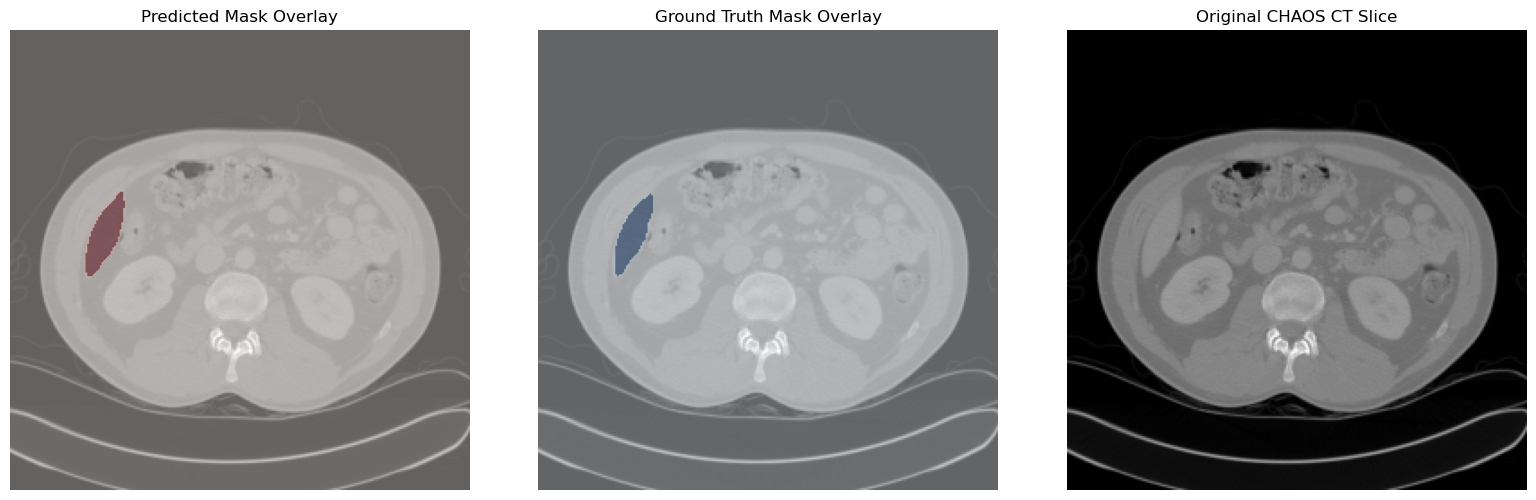

In [437]:
test_chaos_sample(model, device, use_clahe=False)


# U-net Model Evaluation on LITS Dataset

In [332]:
def dice_score(pred, target, smooth=1e-6):
    pred = (pred > 0.5).astype(np.uint8)
    target = (target > 0.5).astype(np.uint8)
    intersection = np.sum(pred * target)
    union = np.sum(pred) + np.sum(target)
    return (2 * intersection + smooth) / (union + smooth)

def iou_score(pred, target, smooth=1e-6):
    pred = (pred > 0.5).astype(np.uint8)
    target = (target > 0.5).astype(np.uint8)
    intersection = np.sum(pred * target)
    union = np.sum(pred) + np.sum(target) - intersection
    return (intersection + smooth) / (union + smooth)


In [334]:
def evaluate_model(model, dataloader, device):
    model.eval()
    dice_scores = []
    iou_scores = []

    with torch.no_grad():
        for img, gt_mask in dataloader:
            img = img.to(device)
            gt_mask = gt_mask.to(device)

            pred = model(img)
            pred_np = pred.squeeze().cpu().numpy()
            gt_np = gt_mask.squeeze().cpu().numpy()

            dice = dice_score(pred_np, gt_np)
            iou = iou_score(pred_np, gt_np)

            dice_scores.append(dice)
            iou_scores.append(iou)

    avg_dice = np.mean(dice_scores)
    avg_iou = np.mean(iou_scores)

    print(f"\n📊 Test Set Evaluation Results:")
    print(f"✅ Average Dice Score: {avg_dice:.4f}")
    print(f"✅ Average IoU Score : {avg_iou:.4f}")
    return avg_dice, avg_iou


In [336]:
evaluate_model(model, test_loader, device)



📊 Test Set Evaluation Results:
✅ Average Dice Score: 0.9504
✅ Average IoU Score : 0.9174


(0.9504378926659487, 0.9174296112172088)

# Fine tune with CHAOS dataset

In [268]:
model.load_state_dict(torch.load("unet_epoch_10_fulldataset_augmented.pth"));
model.to(device);


In [35]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

chaos_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=10, p=0.3),              # Slight rotation
    A.RandomBrightnessContrast(p=0.3),
    A.Resize(256, 256),
    A.Normalize(mean=0.0, std=1.0, max_pixel_value=1.0),
    ToTensorV2()
], additional_targets={'mask': 'mask'})


In [37]:
chaos_val_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=0.0, std=1.0, max_pixel_value=1.0),
    ToTensorV2()
])


In [39]:
import os
import cv2
import numpy as np
import torch
import re
from torch.utils.data import Dataset

class CHAOSSliceDataset(Dataset):
    def __init__(self, image_dir, mask_root, transform=None):
        self.image_dir = image_dir
        self.mask_root = mask_root
        self.transform = transform
        self.missing_count = 0  # ✅ Track missing masks

        self.image_paths = sorted([
            os.path.join(image_dir, f)
            for f in os.listdir(image_dir)
            if f.endswith(".png")
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        try:
            image_path = self.image_paths[idx]
            fname = os.path.basename(image_path)

            # Extract patient ID and slice number
            parts = fname.replace(".png", "").split("_")
            patient_id = parts[1]

            img_match = re.search(r'i(\d{3,})', fname) or re.search(r'IMG-\d{4}-(\d{3,})', fname)
            if img_match:
                slice_num = int(img_match.group(1))
            else:
                slice_num = int(re.findall(r'\d+', fname)[-1])
            slice_str = f"{slice_num:03d}"

            mask_path = os.path.join(self.mask_root, patient_id, "Ground", f"liver_GT_{slice_str}.png")

            # Load image and mask
            img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

            if img is None or mask is None:
                raise FileNotFoundError

            img = img.astype(np.float32) / 255.0
            mask = mask.astype(np.float32) / 255.0

            img = np.expand_dims(img, axis=-1)
            mask = np.expand_dims(mask, axis=-1)

            if self.transform:
                augmented = self.transform(image=img, mask=mask)
                img = augmented["image"]
                mask = augmented["mask"]
                if mask.ndim == 3 and mask.shape[-1] == 1:
                    mask = mask.squeeze(-1).unsqueeze(0)

            return img, mask

        except FileNotFoundError:
            self.missing_count += 1
            new_idx = (idx + 1) % len(self.image_paths)
            return self.__getitem__(new_idx)



In [396]:
chaos_dataset = CHAOSSliceDataset(
    image_dir="../chaos_dataset/1_liver",
    mask_root="../chaos/Train_Sets/CT",
    transform=chaos_transform
)

# Split into train/test
train_size = int(0.8 * len(chaos_dataset))
test_size = len(chaos_dataset) - train_size
chaos_train, chaos_test = random_split(chaos_dataset, [train_size, test_size])

# Set validation transform on test dataset
chaos_test.dataset.transform = chaos_val_transform


In [398]:
chaos_train_loader = DataLoader(chaos_train, batch_size=32, shuffle=True)
chaos_test_loader = DataLoader(chaos_test, batch_size=1, shuffle=False)


In [400]:
for img, mask in chaos_train_loader:
    print("Image shape:", img.shape)
    print("Mask shape: ", mask.shape)
    break


Image shape: torch.Size([32, 1, 256, 256])
Mask shape:  torch.Size([32, 1, 256, 256])


In [196]:
train(model, chaos_train_loader, optimizer, device, epochs=10)



🟢 Epoch 1/10
 Epoch 1 Completed | Avg Loss: 0.0202
 Time taken: 33.51 seconds

🟢 Epoch 2/10
 Epoch 2 Completed | Avg Loss: 0.0181
 Time taken: 32.64 seconds

🟢 Epoch 3/10
 Epoch 3 Completed | Avg Loss: 0.0171
 Time taken: 32.69 seconds

🟢 Epoch 4/10
 Epoch 4 Completed | Avg Loss: 0.0161
 Time taken: 32.73 seconds

🟢 Epoch 5/10
 Epoch 5 Completed | Avg Loss: 0.0158
 Time taken: 32.75 seconds
 Model saved as 'unet_epoch_5.pth'

🟢 Epoch 6/10
 Epoch 6 Completed | Avg Loss: 0.0147
 Time taken: 32.78 seconds

🟢 Epoch 7/10
 Epoch 7 Completed | Avg Loss: 0.0139
 Time taken: 33.10 seconds

🟢 Epoch 8/10
 Epoch 8 Completed | Avg Loss: 0.0132
 Time taken: 32.83 seconds

🟢 Epoch 9/10
 Epoch 9 Completed | Avg Loss: 0.0124
 Time taken: 32.85 seconds

🟢 Epoch 10/10
 Epoch 10 Completed | Avg Loss: 0.0121
 Time taken: 32.83 seconds
 Model saved as 'unet_epoch_10.pth'


In [282]:
torch.cuda.empty_cache()

In [198]:
print(f"⚠️ Missing masks skipped: {chaos_dataset.missing_count}")


⚠️ Missing masks skipped: 10


# Learn from both CHAOS and LITS

In [41]:
from torch.utils.data import ConcatDataset

# LiTS Dataset
lits_dataset = LITSSliceDataset(
    image_dirs=["LITS/1_liver"],
    mask_root="LITS_masks/",
    transform=train_transform  # reuse same augmentation
)

# CHAOS Dataset
chaos_dataset = CHAOSSliceDataset(
    image_dir="../chaos_dataset/1_liver",
    mask_root="../chaos/Train_Sets/CT",
    transform=train_transform
)

# Combine them

combined_dataset = ConcatDataset([lits_dataset, chaos_dataset])



In [43]:
from torch.utils.data import WeightedRandomSampler

# Count how many samples per dataset
n_lits = len(lits_dataset)
n_chaos = len(chaos_dataset)

# Create weights: inverse of dataset size
weights = [1.0 / n_lits] * n_lits + [1.0 / n_chaos] * n_chaos

# Sampler will draw samples such that both datasets contribute equally
sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)


In [45]:
# from torch.utils.data import random_split

# train_size = int(0.9 * len(combined_dataset))
# test_size = len(combined_dataset) - train_size

# combined_train, combined_test = random_split(combined_dataset, [train_size, test_size])


In [47]:
from torch.utils.data import random_split
import torch

# Define split sizes
train_size = int(0.9 * len(combined_dataset))
test_size = len(combined_dataset) - train_size

# Set a generator with a fixed seed
generator = torch.Generator().manual_seed(42)

# Perform the seeded split
combined_train, combined_test = random_split(combined_dataset, [train_size, test_size], generator=generator)


In [55]:
from torch.utils.data import DataLoader

# Inside split
weights_train = weights[:len(combined_train)]
sampler_train = WeightedRandomSampler(weights_train, num_samples=len(weights_train), replacement=True)

train_loader = DataLoader(combined_train, batch_size=32, sampler=sampler_train)
test_loader = DataLoader(combined_test, batch_size=1, shuffle=False)


In [57]:
train(model, train_loader, optimizer, device, epochs=20)



🟢 Epoch 1/20
 Epoch 1 Completed | Avg Loss: 0.0588
 Time taken: 771.67 seconds

🟢 Epoch 2/20
 Epoch 2 Completed | Avg Loss: 0.0553
 Time taken: 760.25 seconds

🟢 Epoch 3/20
 Epoch 3 Completed | Avg Loss: 0.0537
 Time taken: 753.18 seconds

🟢 Epoch 4/20
 Epoch 4 Completed | Avg Loss: 0.0513
 Time taken: 755.19 seconds

🟢 Epoch 5/20
 Epoch 5 Completed | Avg Loss: 0.0493
 Time taken: 751.25 seconds
 Model saved as 'unet_epoch_5.pth'

🟢 Epoch 6/20
 Epoch 6 Completed | Avg Loss: 0.0478
 Time taken: 757.17 seconds

🟢 Epoch 7/20
 Epoch 7 Completed | Avg Loss: 0.0468
 Time taken: 756.97 seconds

🟢 Epoch 8/20
 Epoch 8 Completed | Avg Loss: 0.0454
 Time taken: 756.91 seconds

🟢 Epoch 9/20
 Epoch 9 Completed | Avg Loss: 0.0432
 Time taken: 752.37 seconds

🟢 Epoch 10/20
 Epoch 10 Completed | Avg Loss: 0.0434
 Time taken: 753.52 seconds
 Model saved as 'unet_epoch_10.pth'

🟢 Epoch 11/20
 Epoch 11 Completed | Avg Loss: 0.0430
 Time taken: 755.15 seconds

🟢 Epoch 12/20
 Epoch 12 Completed | Avg Loss

# Model Evaluation on CHAOS Dataset

In [59]:
def evaluate_on_chaos(model, device, image_dir, mask_root, batch_size=1):
    from torch.utils.data import DataLoader
    import numpy as np

    model.eval()

    # Validation/test transform (resize + normalize only)
    val_transform = A.Compose([
        A.Resize(256, 256),
        A.Normalize(mean=0.0, std=1.0, max_pixel_value=1.0),
        ToTensorV2()
    ])

    # Load CHAOS dataset
    chaos_dataset = CHAOSSliceDataset(
        image_dir=image_dir,
        mask_root=mask_root,
        transform=val_transform
    )

    chaos_loader = DataLoader(chaos_dataset, batch_size=batch_size, shuffle=False)

    dice_scores = []
    iou_scores = []

    with torch.no_grad():
        for img, gt_mask in chaos_loader:
            img = img.to(device)
            gt_mask = gt_mask.to(device)

            pred = model(img)
            pred_np = pred.squeeze().cpu().numpy()
            gt_np = gt_mask.squeeze().cpu().numpy()

            # Binarize
            pred_bin = (pred_np > 0.5).astype(np.uint8)
            gt_bin = (gt_np > 0.5).astype(np.uint8)

            # Dice
            intersection = np.sum(pred_bin * gt_bin)
            union = np.sum(pred_bin) + np.sum(gt_bin)
            dice = (2.0 * intersection + 1e-6) / (union + 1e-6)
            dice_scores.append(dice)

            # IoU
            iou = (intersection + 1e-6) / (np.sum(pred_bin + gt_bin > 0) + 1e-6)
            iou_scores.append(iou)

    avg_dice = np.mean(dice_scores)
    avg_iou = np.mean(iou_scores)

    print(f"\n📊 Evaluation on CHAOS Test Set:")
    print(f"✅ Average Dice Score: {avg_dice:.4f}")
    print(f"✅ Average IoU Score : {avg_iou:.4f}")

    return avg_dice, avg_iou


In [61]:
evaluate_on_chaos(
    model=model,
    device=device,
    image_dir="../chaos_dataset/1_liver",
    mask_root="../chaos/Train_Sets/CT"
)



📊 Evaluation on CHAOS Test Set:
✅ Average Dice Score: 0.9549
✅ Average IoU Score : 0.9207


(0.9549159812775986, 0.9207255276802627)

## Evaluate on test set

In [64]:
def evaluate_model(model, dataloader, device):
    model.eval()  # Set model to evaluation mode
    total_iou = 0.0
    total_dice = 0.0
    num_samples = 0

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            preds = (outputs > 0.5).float()

            # IoU and Dice per batch
            intersection = (preds * masks).sum(dim=(1, 2, 3))
            union = ((preds + masks) > 0).float().sum(dim=(1, 2, 3))
            dice = (2 * intersection) / (preds.sum(dim=(1,2,3)) + masks.sum(dim=(1,2,3)) + 1e-8)
            iou = intersection / (union + 1e-8)

            total_iou += iou.sum().item()
            total_dice += dice.sum().item()
            num_samples += images.size(0)

    avg_iou = total_iou / num_samples
    avg_dice = total_dice / num_samples

    print(f"📊 Test Evaluation — Avg IoU: {avg_iou:.4f}, Avg Dice: {avg_dice:.4f}")
    return avg_iou, avg_dice


In [66]:
evaluate_model(model, test_loader, device)


📊 Test Evaluation — Avg IoU: 0.9056, Avg Dice: 0.9451


(0.9056212001626751, 0.9450807394837288)